# Statement of the problem (cylindrical coordinates)

The heterogeneous material under study is a one dimensional idealization of laminated composite materials with elastic constituents.

The aim of this work is to solve the local problems derived from the asymptotic homogenization technique.

For this purpose, we explore the use of Physics-Informed Neural Networks (PINNs) as alternative for the classical approaches.

The local problem is given as follows:

\begin{align}
&\frac{\partial}{\partial y}\left(C(y)\frac{\partial N(y)}{\partial y} + C(y)\right) = 0. \quad y\in \mathscr{Y}\setminus \{y_I\}\\
&\text{Interface conditions - Perfect contact}\nonumber \\
&\left[\left[ N(y) \right]\right] = 0, \quad \left[\left[ C(y)\frac{\partial N(y)}{\partial y} + C(y)\right]\right] = 0. \quad y\in \{y_I\}\\
&\text{Uniqueness condition} \nonumber \\
&<N^{(1)}(y)>_{\mathscr{Y}_1} = <N^{(2)}(y)>_{\mathscr{Y}_2}   = 0, \nonumber \\
\end{align}
where the solution function $N(y)$ is assumed to be 1-periodic with respect to y on the domain of the periodic cell $\mathscr{Y}$.

In Figure 1, we show the domain of the periodic cell under study $\mathscr{Y} = \mathscr{Y}_1\cup \{y_I\}\cup \mathscr{Y}_2$ that characterizes the two-phase composite material.

<img src="Periodic_Cell_Y.png" width="250">

The coefficient $C(y)$ carries information about the elastic properties of the material constituents and is defined as a piecewise constant function, that is

$C(y)= \left\{ \begin{array}{l}
C^{(1)},\; y \in {\mathscr{Y}_1} = [0, y_I[\\
C^{(2)}, \; y \in {\mathscr{Y}_2}= ]y_I, 1].
\end{array} \right.$



In addition, we consider perfect contact conditions at the interface $\{y_I\}$. Here, the operator $\left[\left[\cdot\right]\right]$ describes the jump across the interface $\{y_I\}$ between the constituents.

Based on this configuration, the solution of the local problem $N(y)$ can be proposed as follows:

$N(y)= \left\{ \begin{array}{l}
N^{(1)}(y),\; y \in {\mathscr{Y}_1} = [0, y_I[, \\
N^{(2)}(y), \; y \in {\mathscr{Y}_2} = ]y_I, 1], \\
N^{(1)}(y) = N^{(2)}(y), \; y = y_I,
\end{array} \right.$

and Eqs (1)-(3) can be rewritten as follows,

\begin{align}
&\frac{\partial}{\partial y}\left(C^{(1)}\frac{\partial N^{(1)}(y)}{\partial y} + C^{(1)}\right) = 0, \quad y\in \mathscr{Y}_1 \nonumber \\
&\frac{\partial}{\partial y}\left(C^{(2)}\frac{\partial N^{(2)}(y)}{\partial y} + C^{(2)}\right) = 0, \quad y\in \mathscr{Y}_2\nonumber\\
&N^{(1)}(y_{I}) = N^{(2)}(y_{I}), \nonumber\\
&C^{(1)}\frac{\partial N^{(1)}(y)}{\partial y}|_{(y_{I})} + C^{(1)} = C^{(2)}\frac{\partial N^{(2)}(y)}{\partial y}|_{(y_{I})} + C^{(2)}, \nonumber\\
& \frac{1}{ɛ|Y|}\int_0^{y_I} N^{(1)}(r/ɛ) rdr = \frac{1}{ɛ|Y|}\int_{y_I}^1 N^{(2)}(y) (r/ɛ) rdr  = 0  \nonumber
\end{align}


**Idea For PINNs Architecture**

#-----------

First problem  ($\mathcal{L}^{(1)}_{phy}$ and $\mathcal{L}^{(1)}_{uc}$)

$$\frac{\partial}{\partial y}\left(C^{(1)}\frac{\partial N^{(1)}(y)}{\partial y} + C^{(1)}\right) = 0,   \quad \text{for} \quad y\in \mathscr{Y}_1 $$


$$\frac{1}{ɛ|Y|}\int_0^{y_I} N^{(1)}(r/ɛ) rdr = 0,$$

#-----------

Second problem ($\mathcal{L}^{(2)}_{phy}$ and $\mathcal{L}^{(2)}_{uc}$)

$$\frac{\partial}{\partial y}\left(C^{(2)}\frac{\partial N^{(2)}(y)}{\partial y} + C^{(2)}\right) = 0,  \quad \text{for} \quad y\in \mathscr{Y}_2 $$


$$\frac{1}{ɛ|Y|}\int_{y_I}^1 N^{(2)}(y) (r/ɛ) rdr  = 0. $$
#----------

Interface conditions ($\mathcal{L}_{int}$)
$$N^{(1)}(y_{I}) = N^{(2)}(y_{I}) $$

$$C^{(1)}\frac{\partial N^{(1)}(y)}{\partial y}|_{(y_{I})} + C^{(1)} = C^{(2)}\frac{\partial N^{(2)}(y)}{\partial y}|_{(y_{I})} + C^{(2)} $$


<img src="PINN_1D.png" alt="Description of my figure" width="600">








# Import

In [1]:
import os # Pacote do python para interação com o sistema operacional (ex: criar pastas, criar ou remover arquivos, etc.)
from tqdm import trange

import torch # Pacote python para trabalhos com redes neurais
import torch.nn as nn # Importação da classe nn (uma classe de uma rede neural)
from torchsummary import summary # Utilizado para registrar o progresso do treinamento da rede neural


import numpy as np # Pacote para trabalho com vetores e funções matemáticas
from scipy import integrate # Pacote para métodos numéricos (intergração, resolução de equaçõe diferencias, etc.)
import matplotlib.pyplot as plt # Pacote para plotar resultados


#### Check cuda availability

Verificar se o sistema tem acesso a uma placa gráfica para agilizar os cálculos matriciais (não é obrigatório).

In [ ]:
# print(torch.cuda.is_available())
# print(torch.cuda.device_count())
# print(torch.cuda.get_device_name(0))

In [ ]:
DEVICE = torch.device('cpu') # Definindo o dispositivo disponível do computador (ex: cpu, placa gráfica), em nosso caso é o cpu.

# Hyperparameters

#### Random numbers

In [ ]:
SEED = 1234 # Geração de números pseudo-aleatórios (aplica uma combinação de funções que gera números que parecem aleatórios)

np.random.seed(SEED) # função do pacote numpy para gerar números aleat.
torch.manual_seed(SEED) # Perguntar para Oscar.
torch.backends.cudnn.determinist = True
torch.backends.cudnn.benchmark = False

### NN configuration

In [ ]:
LAYERS = [1,50,50,1] # Começa a definir a estrutura da rede neural (4 camadas no total; 1 input, 1 output e 50 neuônios nas "hidden layers")

EPOCH_ADAMS = 1000 # Número de iterações do treinamento da rede (usando o algoritmo ADAM). ADAM é um algoritmo de otimização dos parâmetros da rede neural.
EPOCH_LBFGS = 10 # Número de iterações do treinamento da rede (usando o algoritmo LBFGS). Sendo LBFGS é mais um algoritmo de otimização.

LOG_STEP=5 # Intervalo entre os registros (vai registrar o progresso a cada 5 iterações.)

### Problem parameters

In [ ]:
y_I = 0.3 # Posição da interface do compósito.
y_a = 0.1
y_b = 1

VF_mat1 = (y_I**2 - y_a**2)/(1 - y_a**2) # Fração volumétrica da fase 1 (ajustado para coordenadas cilíndricas).
VF_mat2 = 1 - VF_mat1 # Fração volumétrica da fase 2.

C_mat1 = 45 # Parametros elásticos do material 1.
C_mat2 = 12 # Parametros elásticos do material 2.

# Dicionário (uma das estruturas de dados do python) que combina todos os parâmetros do compósito
PARAM = {'VF_mat1':VF_mat1, 'VF_mat2':VF_mat2, 'C_mat1':C_mat1, 'C_mat2':C_mat2}

### Build Dataset

#### Train data

In [ ]:
# Definição dos dados de treinamento

N_COLLOCATION = 100 # Número de pontos de colocação (pontos em que a equação diferencial vai ser avaliada)
N_UNIQUENESS = 1000 # Número de pontos de unicidade (pontos em que a condição de unicidade vai ser imposta)
N_BOUNDARY = 1 # Número de pontos da interface (pontos em que a condição de contato vai ser imposta)

# Collocation points
y_collocation_mat1 = np.random.uniform(0,y_I,N_COLLOCATION)[:,None] # Um vetor de pontos aleatórios de colocação antes da interface

y_collocation_mat2 = np.random.uniform(y_I,1,N_COLLOCATION)[:,None] # Um vetor de pontos aleatórios de colocação depois da interface
assert(y_I not in y_collocation_mat2) # Para garantir que o ponto de interface não está no conjunto 2 (pontos depois da interface0.)

# Interface
y_interface = np.array([[y_I]])

# Uniqueness
y_uniqueness1 = np.linspace(0.1, y_I, N_UNIQUENESS)[:,None] # O intervalo em coordenadas cilíndricas não pode começar em 0
y_uniqueness2 = np.linspace(y_I, 1, N_UNIQUENESS)[:,None]

#### Calculation of the effective properties

In [ ]:
N_POINTS = 1000

y_points1 = np.linspace(0.1, y_I, N_POINTS )[:, None]
y_points2 = np.linspace(y_I, 1, N_POINTS )[:, None]

y_points_exact = np.concatenate((y_points1, y_points2))

# PINN Configuration

In [ ]:
class FCN(nn.Module):

    def __init__(self, layers, device, activation = nn.Tanh()):

        super().__init__()

        self.device = device
        self.layers = layers
        self.activation = activation

        # Initialize the neural network as a list
        self.linear = nn.ModuleList([nn.Linear(self.layers[i], self.layers[i+1]) for i in range(len(self.layers)-1)])

        # Xavier Initialization
        for i in range(len(self.layers)-1):
            nn.init.xavier_normal_(self.linear[i].weight.data, gain = 1.0)

            nn.init.zeros_(self.linear[i].bias.data)


    def forward(self, X): # X é o vetor dos inputs da rede neural

        if torch.is_tensor(X) != True:
            X = torch.from_numpy(X) # Converte input não-tensor (ex: NumPy array) para tensor PyTorch


        a = X.float()

        for i in range(len(self.layers)-2):
            z = self.linear[i](a)
            a = self.activation(z)

        NN_pred = self.linear[-1](a)

        return NN_pred

In [ ]:
class PINN(nn.Module):

    def __init__(self, y_collocation_mat1, y_collocation_mat2, y_interface, y_uniqueness1, y_uniqueness2, param, layers, device):

        super().__init__()

        self.device = device

        # Collocation points
        self.y_mat1 = torch.tensor(y_collocation_mat1, requires_grad= True).float().to(self.device)
        self.y_mat2 = torch.tensor(y_collocation_mat2, requires_grad= True).float().to(self.device)

        self.null_mat1 = torch.zeros(self.y_mat1.shape, dtype = torch.float32, requires_grad = False).to(self.device)
        self.null_mat2 = torch.zeros(self.y_mat2.shape, dtype = torch.float32, requires_grad = False).to(self.device)

        # Interface points
        self.y_inter = torch.tensor(y_interface, requires_grad= True).float().to(self.device)
        self.null_inter = torch.zeros(self.y_inter.shape, dtype = torch.float32, requires_grad=False).to(self.device)

        # Uniqueness condition
        self.y_uniq1 = torch.tensor(y_uniqueness1, requires_grad= False).float().to(self.device)
        self.y_uniq2 = torch.tensor(y_uniqueness2, requires_grad= False).float().to(self.device)


        # PDE parameters
        self.VF_mat1 = param['VF_mat1']
        self.VF_mat2 = param['VF_mat2']
        self.C_mat1 = param['C_mat1']
        self.C_mat2 = param['C_mat2']

        ## NN
        self.layers = layers
        self.best   = np.inf
        self.activation = nn.Tanh()

        # Networks initialization
        self.fcn_mat1 = FCN(self.layers, self.device, activation=self.activation)
        self.fcn_mat1.to(self.device)

        self.fcn_mat2 = FCN(self.layers, self.device, activation=self.activation)
        self.fcn_mat2.to(self.device)


        # Parameters summary
        summary(self.fcn_mat1, input_size = (1,1), batch_size = -1)
        summary(self.fcn_mat2, input_size = (1,1), batch_size = -1)


        ### Optimizers
        # Get the parameters as separate lists
        fcp_mat1_param = list(self.fcn_mat1.parameters())
        fcp_mat2_param = list(self.fcn_mat2.parameters())

        # Concatenate the parameters into a single list
        params = fcp_mat1_param + fcp_mat2_param


        ## Adam optimizer for the initial training
        self.optimizer_Adam = torch.optim.Adam(params)

        ## LBFGS Optimizer for fine-tuning
        self.max_iter_LBFGS = 50
        self.optimizer_LBFGS = torch.optim.LBFGS(params, max_iter=self.max_iter_LBFGS, max_eval=self.max_iter_LBFGS,
                                                  tolerance_grad=1.0 * torch.finfo(torch.float32).eps, history_size=50)


        ## loss function
        self.loss_fn = nn.MSELoss(reduction ='mean')

        # Loggers
        self.loss_log = []
        self.loss_collocation_log = []
        self.loss_interface_log = []
        self.loss_uniqueness_condition_log = []

        self.it = 0
        self.best_iter = 0
        self.log_every = 1
        self.pbar = None

    def forward_mat1(self, points):
        N_mat1_pred = self.fcn_mat1(points)
        return N_mat1_pred

    def forward_mat2(self, points):
        N_mat2_pred = self.fcn_mat2(points)
        return N_mat2_pred

    def Loss_Uniqueness_Condition(self): # Para garantir que as médias das funções sejam nulas

        #Predicted
        N_mat1_pred = self.forward_mat1(self.y_uniq1) # Previsões para a função N¹
        N_mat2_pred = self.forward_mat2(self.y_uniq2) # Previsões para a função N²

        # Perform the integration using the trapezoidal rule

        # Incluir
        integral_N_pred1 = (1/(y_I**2-0.1**2))*torch.trapezoid(N_mat1_pred*self.y_uniq1, self.y_uniq1, dim=0) # Integração no domínio para aplicar a condição de unicidade
        integral_N_pred2 = (1/(1-y_I**2))*torch.trapezoid(N_mat2_pred*self.y_uniq1, self.y_uniq2, dim=0) # Adiciona-se aqui a multiplicação pelo

        null1 = torch.zeros(integral_N_pred1.shape, dtype = torch.float32, requires_grad = False).to(self.device) # Vetor de 0s da mesma dimensão que o vetor retornado pela integral
        null2 = torch.zeros(integral_N_pred2.shape, dtype = torch.float32, requires_grad = False).to(self.device)

        loss_uniqueness_condition = self.loss_fn(integral_N_pred1/self.VF_mat1, null1) + self.loss_fn(integral_N_pred2/self.VF_mat2, null2) # Perda referente à diferença entre as médias das funções X e 0

        return loss_uniqueness_condition

    def Loss_Collocation(self):

        #Predicted
        N_mat1_pred = self.forward_mat1(self.y_mat1)
        N_mat2_pred = self.forward_mat2(self.y_mat2)

        N_mat1_pred_y = torch.autograd.grad(N_mat1_pred, self.y_mat1, grad_outputs=torch.ones_like(N_mat1_pred), create_graph=True)[0]
        N_mat1_pred_yy = torch.autograd.grad(N_mat1_pred_y, self.y_mat1, grad_outputs=torch.ones_like(N_mat1_pred_y), create_graph=True)[0]

        N_mat2_pred_y = torch.autograd.grad(N_mat2_pred, self.y_mat2, grad_outputs=torch.ones_like(N_mat2_pred), create_graph=True)[0]
        N_mat2_pred_yy = torch.autograd.grad(N_mat2_pred_y, self.y_mat2, grad_outputs=torch.ones_like(N_mat2_pred_y), create_graph=True)[0]

        equ1 = self.C_mat1*N_mat1_pred_yy
        equ2 = self.C_mat2*N_mat2_pred_yy

        loss_collocation = self.loss_fn(equ1, self.null_mat1) + self.loss_fn(equ2, self.null_mat2)

        return loss_collocation

    def Loss_Interface(self):

        #Predicted
        N_mat1_pred = self.forward_mat1(self.y_inter)
        N_mat2_pred = self.forward_mat2(self.y_inter)

        N_mat1_pred_y = torch.autograd.grad(N_mat1_pred, self.y_inter, grad_outputs=torch.ones_like(N_mat1_pred), create_graph=True)[0]
        N_mat2_pred_y = torch.autograd.grad(N_mat2_pred, self.y_inter, grad_outputs=torch.ones_like(N_mat2_pred), create_graph=True)[0]

        equ1 = self.C_mat1*N_mat1_pred_y + self.C_mat1
        equ2 = self.C_mat2*N_mat2_pred_y + self.C_mat2

        loss_interface1 = self.loss_fn(N_mat1_pred - N_mat2_pred, self.null_inter)
        loss_interface2 = self.loss_fn(equ1 - equ2, self.null_inter)

        loss_interface = loss_interface1 + loss_interface2
        return loss_interface

    def loss(self):
        loss_collocation  = self.Loss_Collocation( )
        loss_uniqueness_condition  = self.Loss_Uniqueness_Condition( )
        loss_interface = self.Loss_Interface( )

        loss_total =  loss_collocation + loss_uniqueness_condition + loss_interface

        return loss_total, loss_collocation, loss_uniqueness_condition, loss_interface

    def compute_loss_and_optimize(self):
        self.optimizer_Adam.zero_grad()
        loss_total, loss_collocation, loss_uniqueness_condition, loss_interface = self.loss()
        loss_total.backward()
        return loss_total, loss_collocation, loss_uniqueness_condition, loss_interface

    def Log(self, loss_total, loss_collocation, loss_uniqueness_condition, loss_interface, pbar, it, log_every):

        # Save the best model
        if loss_total.item() < self.best:
            torch.save(self.state_dict(), "model_laminated1d_pinns.pt")
            self.best = loss_total.item()
            self.best_iter = it

        # Store losses
        self.loss_log.append(loss_total.item())
        self.loss_uniqueness_condition_log.append(loss_uniqueness_condition.item())
        self.loss_collocation_log.append(loss_collocation.item())
        self.loss_interface_log.append(loss_interface.item())

        # Log information
        if it % log_every == 0:
            pbar.set_postfix({'Loss': loss_total.item(),
                            'Residual loss': loss_collocation.item(),
                            'Uniqueness condition': loss_uniqueness_condition.item(),
                            'Interface loss': loss_interface.item()})



    def train(self, nIter_Adam = 100, nIter_LBFGS = 100, log_every = 100):

        self.log_every = log_every
        self.pbar = trange(nIter_Adam + nIter_LBFGS)

        for it in self.pbar:

            self.it = it

            if it < EPOCH_ADAMS: # Initial training with Adam optimizer

                loss_total, loss_collocation, loss_uniqueness_condition, loss_interface = self.compute_loss_and_optimize()
                self.optimizer_Adam.step()
                self.Log(loss_total,  loss_collocation, loss_uniqueness_condition, loss_interface, self.pbar, self.it, self.log_every)


            else: # Fine-tuning with L-BFGS optimizer

                # Print and switch to LBFGS for fine-tuning
                if it == EPOCH_ADAMS:
                    print("Switching to L-BFGS for fine-tuning...")

                def closure():
                    self.optimizer_LBFGS.zero_grad()
                    loss_total, loss_collocation, loss_uniqueness_condition, loss_interface = self.loss()
                    loss_total.backward()

                    self.Log(loss_total, loss_collocation, loss_uniqueness_condition, loss_interface, self.pbar, self.it, self.log_every)

                    return loss_total

                loss_total = self.optimizer_LBFGS.step(closure)


        if self.best_iter < EPOCH_ADAMS:
            self.best_iter = self.best_iter
        else:
            self.best_iter = EPOCH_ADAMS - 1 + (self.best_iter - EPOCH_ADAMS + 1)*self.max_iter_LBFGS

        print("The best model is obtained in EPOCH ="+f"{self.best_iter}.")
        return self.best_iter, self.loss_log


    def Effective_Properties(self, points1, points2, verbose = True):

        y_mat1 = torch.tensor(points1, requires_grad=True).float().to(DEVICE)
        y_mat2 = torch.tensor(points2, requires_grad=True).float().to(DEVICE)

        N_mat1_pred = self.forward_mat1(y_mat1)
        N_mat2_pred = self.forward_mat2(y_mat2)

        N_mat1_pred_y = torch.autograd.grad(N_mat1_pred, y_mat1, grad_outputs=torch.ones_like(N_mat1_pred), create_graph=True)[0]
        N_mat2_pred_y = torch.autograd.grad(N_mat2_pred, y_mat2, grad_outputs=torch.ones_like(N_mat2_pred), create_graph=True)[0]

        Exp_mat1 = self.C_mat1 + self.C_mat1*N_mat1_pred_y
        Exp_mat2 = self.C_mat2 + self.C_mat2*N_mat2_pred_y

        # Via_1
        # Perform the integration using the trapezoidal rule
        integral_Exp1 = torch.trapezoid(Exp_mat1, y_mat1, dim=0)
        integral_Exp2 = torch.trapezoid(Exp_mat2, y_mat2, dim=0)
        # Sum the integrals
        C_eff = integral_Exp1 + integral_Exp2

        # # Via_2 (In this case N_mat1_pred_y and N_mat2_pred_y are constant values !)
        # C_eff_aux = torch.sum(self.VF_mat1*Exp_mat1 + self.VF_mat2*Exp_mat2).view([1,])/Exp_mat1.shape[0]

        # assert(C_eff == C_eff_aux)

        C_eff=C_eff.detach().cpu().numpy()

        N_pred = torch.concatenate((N_mat1_pred,N_mat2_pred))
        N_pred=N_pred.detach().cpu().numpy()

        return C_eff[0], N_pred



### Train the model

In [ ]:
# Model definition
model = PINN(y_collocation_mat1, y_collocation_mat2, y_interface, y_uniqueness1, y_uniqueness2,
            param = PARAM, layers = LAYERS, device = DEVICE)
model.to(DEVICE)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                [-1, 1, 50]             100
              Tanh-2                [-1, 1, 50]               0
            Linear-3                [-1, 1, 50]           2,550
              Tanh-4                [-1, 1, 50]               0
            Linear-5                 [-1, 1, 1]              51
Total params: 2,701
Trainable params: 2,701
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.01
Estimated Total Size (MB): 0.01
----------------------------------------------------------------
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                [-1, 1, 50]             100
              Tanh-2                [-1, 1, 5

PINN(
  (activation): Tanh()
  (fcn_mat1): FCN(
    (activation): Tanh()
    (linear): ModuleList(
      (0): Linear(in_features=1, out_features=50, bias=True)
      (1): Linear(in_features=50, out_features=50, bias=True)
      (2): Linear(in_features=50, out_features=1, bias=True)
    )
  )
  (fcn_mat2): FCN(
    (activation): Tanh()
    (linear): ModuleList(
      (0): Linear(in_features=1, out_features=50, bias=True)
      (1): Linear(in_features=50, out_features=50, bias=True)
      (2): Linear(in_features=50, out_features=1, bias=True)
    )
  )
  (loss_fn): MSELoss()
)

In [ ]:
# Training
bestIter, Loss = model.train(nIter_Adam=EPOCH_ADAMS, nIter_LBFGS = EPOCH_LBFGS, log_every=LOG_STEP)

 99%|█████████▊| 995/1010 [00:13<00:00, 102.09it/s, Loss=0.00197, Residual loss=0.000847, Uniqueness condition=0.00106, Interface loss=6.81e-5]

Switching to L-BFGS for fine-tuning...


100%|██████████| 1010/1010 [00:14<00:00, 69.50it/s, Loss=1.11e-5, Residual loss=9.6e-6, Uniqueness condition=1.41e-6, Interface loss=3.6e-8]

The best model is obtained in EPOCH =1149.


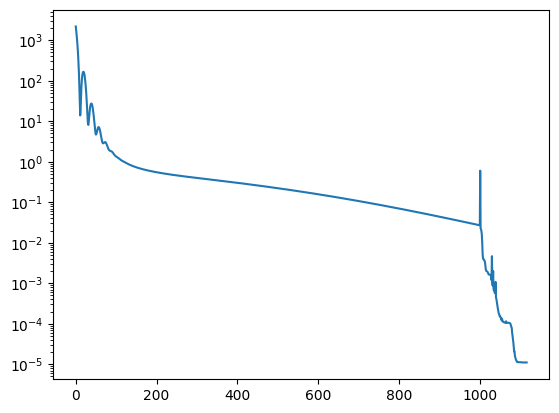

In [ ]:
plt.semilogy(Loss)

# Test the model

In [ ]:
model_test = PINN(y_collocation_mat1, y_collocation_mat2, y_interface, y_uniqueness1, y_uniqueness2,
            param = PARAM, layers = LAYERS, device = DEVICE)
model_test.to(DEVICE)
model_test.load_state_dict(torch.load("./model_laminated1d_pinns.pt"))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                [-1, 1, 50]             100
              Tanh-2                [-1, 1, 50]               0
            Linear-3                [-1, 1, 50]           2,550
              Tanh-4                [-1, 1, 50]               0
            Linear-5                 [-1, 1, 1]              51
Total params: 2,701
Trainable params: 2,701
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.01
Estimated Total Size (MB): 0.01
----------------------------------------------------------------
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                [-1, 1, 50]             100
              Tanh-2                [-1, 1, 5

<All keys matched successfully>

In [ ]:
C_eff_pred, Chi_pred= model_test.Effective_Properties(y_points1,y_points2)

print("Exact effective coefficient:", C_mat1*C_mat2/(VF_mat1*C_mat2+VF_mat2*C_mat1))
print("Predicted effective coefficient:", C_eff_pred)


Exact effective coefficient: 12.755905511811022
Predicted effective coefficient: 12.515751


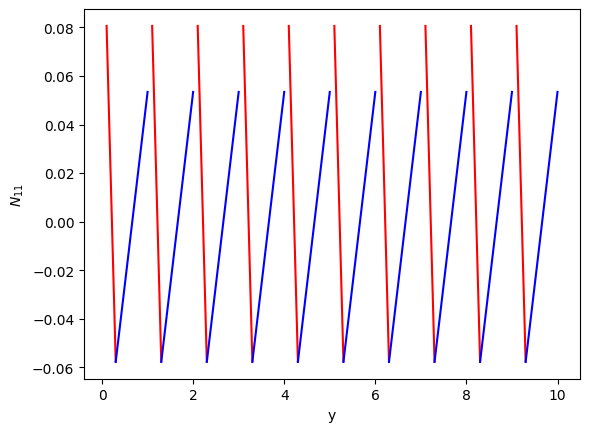

In [ ]:
y_1 = np.linspace(0.1, y_I, 100)
y_2 = np.linspace(y_I, 1, 100)
# plt.plot(y_1, model_test.forward_mat1(torch.tensor(y_1[:,None])).detach().cpu().numpy())
# plt.plot(y_2, model_test.forward_mat2(torch.tensor(y_2[:,None])).detach().cpu().numpy())
plt.xlabel('y')
plt.ylabel(r'$N_{11}$')

for i in range(10):
  plt.plot(y_1 + i, model_test.forward_mat1(torch.tensor(y_1[:,None])).detach().cpu().numpy(), color = "red")
  plt.plot(y_2 + i, model_test.forward_mat2(torch.tensor(y_2[:,None])).detach().cpu().numpy(), color = "blue")

In [ ]:
model_test.forward_mat1(torch.tensor([model_test.y_inter]))
model_test.Loss_Uniqueness_Condition()

tensor(1.4128e-06, grad_fn=<AddBackward0>)

# Ambiente de testes

In [ ]:
# Define os pontos radiais e a função
r = torch.linspace(1, 10, 10)  # self.y_uniq1
f_r = r                      # Chi_mat1_pred

# Integração sem o Jacobiano (incorreta)
incorrect_result = torch.trapezoid(f_r, r, dim=0)  # Resultado ≈ 0.333 (errado)

# Integração com o Jacobiano (correta)
correct_result = torch.trapezoid(f_r * r, r, dim=0)  # Resultado ≈ 0.250 (correto)

print(r)
print('-'*100)
#print(f_r)
print('-'*100)
print(r * r) # Logo, a multiplicação entre vetores multiplica os termos um a um

tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
tensor([  1.,   4.,   9.,  16.,  25.,  36.,  49.,  64.,  81., 100.])
